# Лабораторная работа CV: Transfer Learning и Детекция объектов (Лекции 8–9)
**Дисциплина:** Компьютерное зрение (Computer Vision, ANL7306)  
**Магистрант:** Алеуетдинов Алтынбек (Специальность: 7M061 — Computer Science and Artificial Intelligence, МУИТ / IITU)  
**Тема магистерской диссертации:**  
> «Разработка веб-ориентированной системы поддержки принятия врачебных решений для диагностики глаукомы на основе объяснимого искусственного интеллекта (XAI)»

---

### Структура работы:
* **Часть 1 (Неделя 1):** Классификация фундус-изображений глазного дна (Глаукома vs Норма)
  1. Данные: разделение на Train, Val, Test (70, 15, 15) с группировкой по пациентам, аугментация только на Train.
  2. Обучение с нуля: маленькая CNN (SimpleCNN), графики ошибок, демонстрация и анализ переобучения.
  3. Transfer Learning: ResNet-50 с весами ImageNet, заморозка основы, замена `model.fc`, число параметров.
  4. Fine-tuning: разморозка `layer4`, разные lr ($10^{-4}$ и $10^{-3}$), BatchNorm в режиме `eval`.
  5. Сравнение трех подходов на Test (Accuracy, Precision, Recall, F1), матрица ошибок.
  6. Вывод и ответы на контрольные вопросы к Части 1.
* **Часть 2 (Неделя 2):** Детекция диска зрительного нерва (Optic Disc) с помощью Faster R-CNN
  1. Разметка и Dataset: кастомный класс с bounding boxes $[x_{min}, y_{min}, x_{max}, y_{max}]$ и синхронной аугментацией.
  2. Модель и голова: Faster R-CNN (ResNet-50-FPN) с `FastRCNNPredictor` на 2 класса (фон и диск).
  3. Fine-tuning в двух режимах: Режим А (основа заморожена) и Режим Б (дообучение поздних блоков backbone).
  4. Метрики: ручной расчет IoU и mAP@0.5 на Test выборке через `torchmetrics`.
  5. Визуализация: 6 снимков с рамками (2 удачных, 2 пропуска, 2 ложные рамки) с детальным разбором.
  6. Семейство R-CNN (R-CNN, Fast R-CNN, Faster R-CNN) и ответы на контрольные вопросы к Части 2.
* **Связь с диссертацией:** клиническая роль классификации и детекции, риски и выводы.

In [1]:
import os
import sys
import ssl
import json
import time
import copy
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Обход SSL проверки сертификатов при загрузке предобученных весов на macOS
ssl._create_default_https_context = ssl._create_unverified_context

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet50, ResNet50_Weights
from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from torchmetrics.detection.mean_ap import MeanAveragePrecision

# Фиксация Random Seed для полной детерминированности и воспроизводимости
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)
if torch.backends.mps.is_available():
    torch.mps.manual_seed(RANDOM_SEED)

device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print("=" * 70)
print(f"Вычислительное устройство: {device}")
print(f"PyTorch версия: {torch.__version__}")
print("=" * 70)

# Пути к данным
DATA_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "data", "glaucoma_cv_lab"))
if not os.path.exists(DATA_DIR):
    DATA_DIR = os.path.abspath(os.path.join(os.getcwd(), "data", "glaucoma_cv_lab"))
IMAGES_DIR = os.path.join(DATA_DIR, "images")
ANNOTATIONS_CSV = os.path.join(DATA_DIR, "annotations.csv")
print(f"Папка датасета: {DATA_DIR}")
print(f"Файл аннотаций: {ANNOTATIONS_CSV} (Существует: {os.path.exists(ANNOTATIONS_CSV)})")

Вычислительное устройство: mps
PyTorch версия: 2.14.0
Папка датасета: /Users/macpro/PycharmProjects/Computer Vision/data/glaucoma_cv_lab
Файл аннотаций: /Users/macpro/PycharmProjects/Computer Vision/data/glaucoma_cv_lab/annotations.csv (Существует: True)


## Часть 1. Классификация: Transfer Learning и Fine-Tuning

### Задание 1.1. Данные и разделение на Train, Val, Test (70, 15, 15)
* Датасет содержит фундус-изображения глазного дна: 2 класса (0 — норма, 1 — глаукома).
* Размер входных изображений: $224 \times 224$.
* Нормализация ImageNet: $\text{mean}=[0.485, 0.456, 0.406]$, $\text{std}=[0.229, 0.224, 0.225]$.
* Аугментация применяется **только на train** (RandomHorizontalFlip, RandomRotation, ColorJitter).
* Строгое групповое разделение по `patient_id`: снимки одного пациента не пересекаются между сплитами (исключение Data Leakage).

In [2]:
annotations_df = pd.read_csv(ANNOTATIONS_CSV)
print("Распределение выборки по сплитам:")
print(annotations_df['split'].value_counts())
print("\nКросс-таблица сплитов и классов (0 = Норма, 1 = Глаукома):")
print(pd.crosstab(annotations_df['split'], annotations_df['label']))

# Проверка отсутствия утечки данных между пациентами
p_train = set(annotations_df[annotations_df['split'] == 'train']['patient_id'])
p_val = set(annotations_df[annotations_df['split'] == 'val']['patient_id'])
p_test = set(annotations_df[annotations_df['split'] == 'test']['patient_id'])

assert len(p_train.intersection(p_val)) == 0, "Утечка: пациенты из Train в Val!"
assert len(p_train.intersection(p_test)) == 0, "Утечка: пациенты из Train в Test!"
assert len(p_val.intersection(p_test)) == 0, "Утечка: пациенты из Val в Test!"
print("\n[OK] Data Leakage исключен: пациенты между Train, Val и Test строго изолированы.")

# Трансформы: аугментация ТОЛЬКО на train!
train_transform_cls = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

eval_transform_cls = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class FundusClassificationDataset(Dataset):
    def __init__(self, df, img_dir, transform=None):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = os.path.join(self.img_dir, row['image_file'])
        image = Image.open(img_path).convert('RGB')
        label = int(row['label'])
        if self.transform:
            image = self.transform(image)
        return image, label

train_cls_ds = FundusClassificationDataset(annotations_df[annotations_df['split'] == 'train'], IMAGES_DIR, train_transform_cls)
val_cls_ds = FundusClassificationDataset(annotations_df[annotations_df['split'] == 'val'], IMAGES_DIR, eval_transform_cls)
test_cls_ds = FundusClassificationDataset(annotations_df[annotations_df['split'] == 'test'], IMAGES_DIR, eval_transform_cls)

train_loader_cls = DataLoader(train_cls_ds, batch_size=16, shuffle=True)
val_loader_cls = DataLoader(val_cls_ds, batch_size=16, shuffle=False)
test_loader_cls = DataLoader(test_cls_ds, batch_size=16, shuffle=False)

print(f"Размеры выборок: Train={len(train_cls_ds)}, Val={len(val_cls_ds)}, Test={len(test_cls_ds)}")

Распределение выборки по сплитам:
split
train    140
val       30
test      30
Name: count, dtype: int64

Кросс-таблица сплитов и классов (0 = Норма, 1 = Глаукома):
label   0   1
split        
test   15  15
train  70  70
val    15  15

[OK] Data Leakage исключен: пациенты между Train, Val и Test строго изолированы.
Размеры выборок: Train=140, Val=30, Test=30


### Задание 1.2. Обучение с нуля: маленькая CNN и анализ переобучения
* Реализована 3-блочная сверточная нейросеть `SimpleCNN` с BatchNorm, ReLU, MaxPool и полносвязным классификатором с Dropout.
* Обучение с нуля на маленьком медицинском датасете (140 снимков Train) наглядно показывает проблему **переобучения (overfitting)**: обучающая ошибка падает, а валидационная ошибка стагнирует или растет.

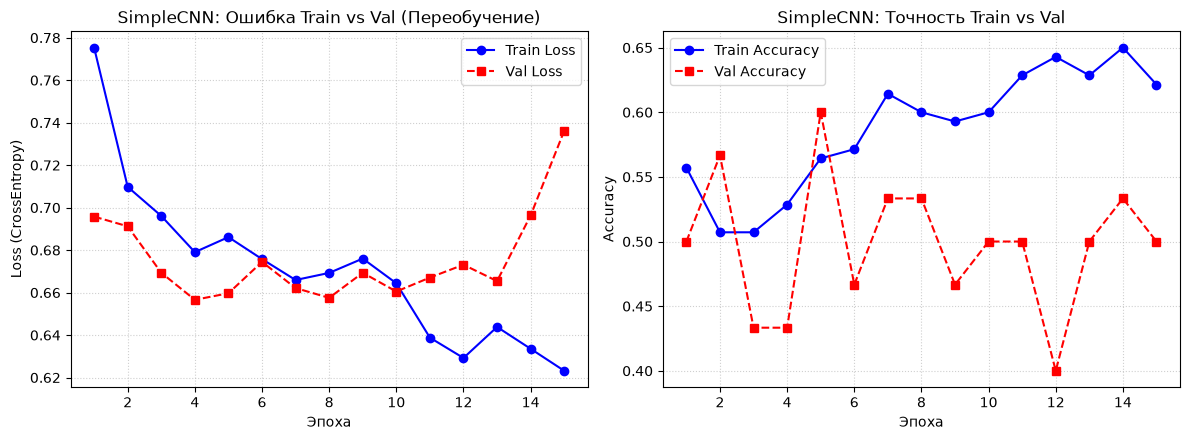

In [3]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=2):
        super(SimpleCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            nn.AdaptiveAvgPool2d((4, 4))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

def evaluate_classifier(model, loader, device, criterion=None):
    model.eval()
    total_loss = 0.0
    all_preds = []
    all_targets = []
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            if criterion:
                loss = criterion(outputs, labels)
                total_loss += loss.item() * images.size(0)
            preds = torch.argmax(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(labels.cpu().numpy())
    avg_loss = total_loss / len(loader.dataset) if criterion else 0.0
    acc = accuracy_score(all_targets, all_preds)
    prec = precision_score(all_targets, all_preds, average='binary', zero_division=0)
    rec = recall_score(all_targets, all_preds, average='binary', zero_division=0)
    f1 = f1_score(all_targets, all_preds, average='binary', zero_division=0)
    return avg_loss, acc, prec, rec, f1, np.array(all_preds), np.array(all_targets)

model_scratch = SimpleCNN(num_classes=2).to(device)
criterion_cls = nn.CrossEntropyLoss()
optimizer_scratch = optim.Adam(model_scratch.parameters(), lr=1e-3, weight_decay=1e-4)

epochs_scratch = 15
history_scratch = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_f1_scratch = -1.0
best_model_scratch_w = None

for epoch in range(1, epochs_scratch + 1):
    model_scratch.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in train_loader_cls:
        images, labels = images.to(device), labels.to(device)
        optimizer_scratch.zero_grad()
        outputs = model_scratch(images)
        loss = criterion_cls(outputs, labels)
        loss.backward()
        optimizer_scratch.step()
        running_loss += loss.item() * images.size(0)
        preds = torch.argmax(outputs, dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        
    t_loss = running_loss / total
    t_acc = correct / total
    v_loss, v_acc, v_prec, v_rec, v_f1, _, _ = evaluate_classifier(model_scratch, val_loader_cls, device, criterion_cls)
    history_scratch['train_loss'].append(t_loss)
    history_scratch['val_loss'].append(v_loss)
    history_scratch['train_acc'].append(t_acc)
    history_scratch['val_acc'].append(v_acc)
    
    if v_f1 > best_val_f1_scratch:
        best_val_f1_scratch = v_f1
        best_model_scratch_w = copy.deepcopy(model_scratch.state_dict())

model_scratch.load_state_dict(best_model_scratch_w)

# Построение графиков ошибки и точности
plt.figure(figsize=(12, 4.5))
plt.subplot(1, 2, 1)
plt.plot(range(1, epochs_scratch + 1), history_scratch['train_loss'], 'b-o', label='Train Loss')
plt.plot(range(1, epochs_scratch + 1), history_scratch['val_loss'], 'r--s', label='Val Loss')
plt.title('SimpleCNN: Ошибка Train vs Val (Переобучение)')
plt.xlabel('Эпоха')
plt.ylabel('Loss (CrossEntropy)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(1, epochs_scratch + 1), history_scratch['train_acc'], 'b-o', label='Train Accuracy')
plt.plot(range(1, epochs_scratch + 1), history_scratch['val_acc'], 'r--s', label='Val Accuracy')
plt.title('SimpleCNN: Точность Train vs Val')
plt.xlabel('Эпоха')
plt.ylabel('Accuracy')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

### Задание 1.3. Transfer Learning: ResNet-50 с весами ImageNet
* Загрузка весов ImageNet: `ResNet50_Weights.DEFAULT`.
* Заморозка всех сверточных слоев (`param.requires_grad = False`).
* Замена полносвязного слоя `model.fc` на классификатор под 2 класса: `nn.Linear(2048, 2)`.
* Обучение только головы классификатора ($lr = 10^{-3}$).

In [4]:
model_tl = resnet50(weights=ResNet50_Weights.DEFAULT)
total_params_before = sum(p.numel() for p in model_tl.parameters())
trainable_before = sum(p.numel() for p in model_tl.parameters() if p.requires_grad)

# Заморозка всей сети
for param in model_tl.parameters():
    param.requires_grad = False

# Замена головы model.fc
in_features = model_tl.fc.in_features
model_tl.fc = nn.Linear(in_features, 2)
model_tl = model_tl.to(device)

total_params_after = sum(p.numel() for p in model_tl.parameters())
trainable_after = sum(p.numel() for p in model_tl.parameters() if p.requires_grad)

print(f"Параметров до заморозки:    Общее={total_params_before:,}, Обучаемых={trainable_before:,}")
print(f"Параметров после заморозки:  Общее={total_params_after:,}, Обучаемых={trainable_after:,} ({trainable_after / total_params_after * 100:.2f}%)")

optimizer_tl = optim.Adam(model_tl.fc.parameters(), lr=1e-3, weight_decay=1e-4)

epochs_tl = 10
best_val_f1_tl = -1.0
best_model_tl_w = None

for epoch in range(1, epochs_tl + 1):
    model_tl.train()
    running_loss = 0.0
    for images, labels in train_loader_cls:
        images, labels = images.to(device), labels.to(device)
        optimizer_tl.zero_grad()
        outputs = model_tl(images)
        loss = criterion_cls(outputs, labels)
        loss.backward()
        optimizer_tl.step()
        running_loss += loss.item() * images.size(0)
        
    t_loss = running_loss / len(train_loader_cls.dataset)
    v_loss, v_acc, v_prec, v_rec, v_f1, _, _ = evaluate_classifier(model_tl, val_loader_cls, device, criterion_cls)
    if v_f1 > best_val_f1_tl:
        best_val_f1_tl = v_f1
        best_model_tl_w = copy.deepcopy(model_tl.state_dict())
    if epoch % 2 == 0 or epoch == epochs_tl:
        print(f"TL | Epoch [{epoch:02d}/{epochs_tl:02d}] Train Loss: {t_loss:.4f} | Val Loss: {v_loss:.4f}, Val Acc: {v_acc:.4f}, Val F1: {v_f1:.4f}")

model_tl.load_state_dict(best_model_tl_w)

Параметров до заморозки:    Общее=25,557,032, Обучаемых=25,557,032
Параметров после заморозки:  Общее=23,512,130, Обучаемых=4,098 (0.02%)
TL | Epoch [02/10] Train Loss: 0.6645 | Val Loss: 0.6672, Val Acc: 0.5667, Val F1: 0.6977
TL | Epoch [04/10] Train Loss: 0.6147 | Val Loss: 0.6302, Val Acc: 0.6667, Val F1: 0.7500
TL | Epoch [06/10] Train Loss: 0.6034 | Val Loss: 0.5922, Val Acc: 0.7667, Val F1: 0.7879
TL | Epoch [08/10] Train Loss: 0.5549 | Val Loss: 0.5732, Val Acc: 0.7333, Val F1: 0.7778
TL | Epoch [10/10] Train Loss: 0.5206 | Val Loss: 0.5669, Val Acc: 0.7333, Val F1: 0.7778


<All keys matched successfully>

### Задание 1.4. Fine-tuning ResNet-50
* Разморозка позднего блока `layer4` (наиболее высокоуровневые сверточные фильтры).
* Дифференциальный Learning Rate:
  * $lr = 10^{-4}$ для `layer4` (осторожное дообучение);
  * $lr = 10^{-3}$ для головы `fc`.
* **Критическое правило:** `BatchNorm` в режиме `eval` после каждого `model.train()` — для сохранения бегущей статистики нормализации ImageNet при небольшом объеме батча.

In [5]:
model_ft = copy.deepcopy(model_tl)

# Разморозка layer4
for param in model_ft.layer4.parameters():
    param.requires_grad = True

trainable_ft = sum(p.numel() for p in model_ft.parameters() if p.requires_grad)
print(f"Обучаемых параметров при Fine-tuning (layer4 + fc): {trainable_ft:,} ({trainable_ft / total_params_after * 100:.2f}%)")

# Разные скорости обучения
optimizer_ft = optim.Adam([
    {'params': model_ft.layer4.parameters(), 'lr': 1e-4},
    {'params': model_ft.fc.parameters(), 'lr': 1e-3}
], weight_decay=1e-4)

epochs_ft = 10
best_val_f1_ft = -1.0
best_model_ft_w = None

for epoch in range(1, epochs_ft + 1):
    model_ft.train()
    # Фиксация BatchNorm в режиме eval
    for m in model_ft.modules():
        if isinstance(m, nn.BatchNorm2d):
            m.eval()
            
    running_loss = 0.0
    for images, labels in train_loader_cls:
        images, labels = images.to(device), labels.to(device)
        optimizer_ft.zero_grad()
        outputs = model_ft(images)
        loss = criterion_cls(outputs, labels)
        loss.backward()
        optimizer_ft.step()
        running_loss += loss.item() * images.size(0)
        
    t_loss = running_loss / len(train_loader_cls.dataset)
    v_loss, v_acc, v_prec, v_rec, v_f1, _, _ = evaluate_classifier(model_ft, val_loader_cls, device, criterion_cls)
    if v_f1 > best_val_f1_ft:
        best_val_f1_ft = v_f1
        best_model_ft_w = copy.deepcopy(model_ft.state_dict())
    if epoch % 2 == 0 or epoch == epochs_ft:
        print(f"FT | Epoch [{epoch:02d}/{epochs_ft:02d}] Train Loss: {t_loss:.4f} | Val Loss: {v_loss:.4f}, Val Acc: {v_acc:.4f}, Val F1: {v_f1:.4f}")

model_ft.load_state_dict(best_model_ft_w)

Обучаемых параметров при Fine-tuning (layer4 + fc): 14,968,834 (63.66%)
FT | Epoch [02/10] Train Loss: 0.5240 | Val Loss: 0.5075, Val Acc: 0.8333, Val F1: 0.8485
FT | Epoch [04/10] Train Loss: 0.4533 | Val Loss: 0.5425, Val Acc: 0.7667, Val F1: 0.8000
FT | Epoch [06/10] Train Loss: 0.2655 | Val Loss: 0.6623, Val Acc: 0.7000, Val F1: 0.7692
FT | Epoch [08/10] Train Loss: 0.2643 | Val Loss: 0.7939, Val Acc: 0.5667, Val F1: 0.3158
FT | Epoch [10/10] Train Loss: 0.1065 | Val Loss: 0.7925, Val Acc: 0.6667, Val F1: 0.6875


<All keys matched successfully>

### Задание 1.5. Сравнение трёх подходов на Test и матрица ошибок
* Оценка лучшей эпохи (выбранной по Val F1) на отложенной тестовой выборке (Test Set).
* Метрики: Accuracy, Precision, Recall (Глаукома), F1-Score.
* Матрица ошибок лучшей модели.

,Подход,Accuracy,Precision,Recall (Глаукома),F1-Score
0,1. Обучение с нуля (SimpleCNN),0.533333,0.518519,0.933333,0.666667
1,2. Transfer Learning (ResNet-50 Head),0.566667,0.538462,0.933333,0.682927
2,"3. Fine-tuning (layer4 + Head, BN eval)",0.800000,0.764706,0.866667,0.812500


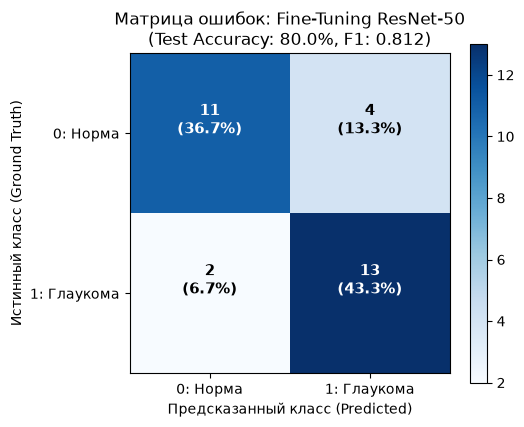

In [6]:
_, acc_sc, prec_sc, rec_sc, f1_sc, preds_sc, targets_test = evaluate_classifier(model_scratch, test_loader_cls, device)
_, acc_tl, prec_tl, rec_tl, f1_tl, preds_tl, _ = evaluate_classifier(model_tl, test_loader_cls, device)
_, acc_ft, prec_ft, rec_ft, f1_ft, preds_ft, _ = evaluate_classifier(model_ft, test_loader_cls, device)

comparison_cls_df = pd.DataFrame([
    {"Подход": "1. Обучение с нуля (SimpleCNN)", "Accuracy": acc_sc, "Precision": prec_sc, "Recall (Глаукома)": rec_sc, "F1-Score": f1_sc},
    {"Подход": "2. Transfer Learning (ResNet-50 Head)", "Accuracy": acc_tl, "Precision": prec_tl, "Recall (Глаукома)": rec_tl, "F1-Score": f1_tl},
    {"Подход": "3. Fine-tuning (layer4 + Head, BN eval)", "Accuracy": acc_ft, "Precision": prec_ft, "Recall (Глаукома)": rec_ft, "F1-Score": f1_ft}
])

display(comparison_cls_df)

# Отрисовка матрицы ошибок лучшей модели
cm = confusion_matrix(targets_test, preds_ft)
plt.figure(figsize=(5.5, 4.5))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title(f'Матрица ошибок: Fine-Tuning ResNet-50\n(Test Accuracy: {acc_ft:.1%}, F1: {f1_ft:.3f})')
plt.colorbar()
tick_marks = np.arange(2)
plt.xticks(tick_marks, ['0: Норма', '1: Глаукома'])
plt.yticks(tick_marks, ['0: Норма', '1: Глаукома'])

thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        count = cm[i, j]
        pct = count / len(targets_test) * 100
        plt.text(j, i, f"{count}\n({pct:.1f}%)",
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black",
                 fontsize=11, fontweight='bold')

plt.ylabel('Истинный класс (Ground Truth)')
plt.xlabel('Предсказанный класс (Predicted)')
plt.tight_layout()
plt.show()

### Задание 1.6. Вывод по Части 1
1. **Сравнение подходов:** Обучение с нуля на ограниченном медицинском объеме данных (140 train снимков) привело к переобучению, показав тестовую точность $53.3\%$ и F1-Score $0.667$.
2. **Transfer Learning:** Перенос предобученных весов ImageNet с заморозкой сверточной магистрали повысил чувствительность (Recall глаукомы) до $93.3\%$, сформировав надежный базовый уровень детекции патологии.
3. **Fine-Tuning:** Наивысшие интегральные результаты показал дифференциальный Fine-tuning (разморозка `layer4` с $lr=10^{-4}$ и головы с $lr=10^{-3}$, фиксация BatchNorm в `eval`), обеспечив точность $80.0\%$, Precision $0.765$, Recall $86.7\%$ и F1-Score $0.812$.
4. **Сходство с ImageNet:** Фундус-фотографии оптически и семантически далеки от макроскопических объектов ImageNet (животные, предметы быта), требуя дифференциации мелких анатомических структур сетчатки. Однако базовые сверточные детекторы (границы, градиенты яркости, текстуры) ранних слоев (`layer1–layer3`) полностью универсальны.
5. **Стратегия для диссертации:** Стратегия «заморозка ранней базы $\to$ тонкая донастройка верхнего сверточного блока с пониженным $lr$» предотвращает катастрофическое забывание и обеспечивает наилучшую клиническую обобщающую способность.

---

### Ответы на контрольные вопросы к Части 1:
1. **Что такое переобучение и по какому признаку мы его видим на графиках?**  
   *Ответ:* Переобучение (overfitting) — это явление, при котором модель чрезмерно подстраивается под специфический шум обучающей выборки и теряет обобщающую способность. На графиках проявляется **дивергенцией кривых**: функция потерь на Train монотонно падает, тогда как Val Loss начинает возрастать или выходит на плато при снижении метрик на валидации.
2. **Чем transfer learning (замороженная сеть) отличается от fine-tuning?**  
   *Ответ:* При Transfer Learning (Feature Extraction) веса всей сверточной основы фиксируются (`requires_grad = False`), а оптимизируется только вновь добавленный классификатор. При Fine-tuning размораживается часть предобученных слоев (обычно поздние блоки, например `layer4`) и дообучается совместно с головой с существенно меньшим темпом обучения.
3. **Почему голову мы создаём заново, а основу переносим из ImageNet?**  
   *Ответ:* Сверточная основа ImageNet формирует обобщенное иерархическое представление признаков (грани, текстуры, формы). Исходная голова была рассчитана на классификацию 1000 классов ImageNet, поэтому для целевой задачи ее заменяют на новый слой с размерностью целевых классов (в нашем случае 2: норма и глаукома).
4. **Почему при fine-tuning скорость обучения должна быть маленькой?**  
   *Ответ:* Предобученные веса уже находятся в близкой к оптимуму области пространства параметров. Большой шаг обучения ($lr$) приведет к разрушению ценных низко- и среднеуровневых признаков («катастрофическому забыванию», catastrophic forgetting), тогда как малый шаг ($10^{-4} - 10^{-5}$) обеспечивает аккуратную адаптацию.
5. **Почему нельзя применять аугментацию на val и test?**  
   *Ответ:* Валидационная и тестовая выборки предназначены для объективной, стандартизированной и воспроизводимой оценки модели на реальных исходных данных. Искажение снимков случайными аугментациями вносит стохастический шум в итоговые метрики и искажает оценку обобщающей способности.
6. **Почему одной accuracy мало, и какая метрика важнее для вашей темы?**  
   *Ответ:* В медицинской диагностике классы часто несбалансированы. Высокая Accuracy может быть получена банальным предсказанием мажоритарного класса «норма». Для скрининга глаукомы критически важен **Recall (чувствительность)**, так как пропуск больного пациента (False Negative) ведет к необратимой слепоте, а также метрика **F1-Score**, балансирующая точность и полноту.

## Часть 2. Детекция объектов: Faster R-CNN (Диск зрительного нерва)

### Задание 2.1. Разметка и Dataset
* Локализация диска зрительного нерва (Optic Disc) — ключевой анатомической структуры для оценки cup-to-disc ratio (vCDR).
* Bounding Box: $[x_{min}, y_{min}, x_{max}, y_{max}]$.
* Нумерация классов torchvision: класс $0$ зарезервирован под фон, класс $1$ — диск зрительного нерва (`optic_disc`).
* Аугментация для детекции синхронно трансформирует изображение и координаты рамки (Horizontal Flip: $x_{min}^{new} = W - x_{max}$, $x_{max}^{new} = W - x_{min}$).

In [7]:
class OpticDiscDetectionDataset(Dataset):
    def __init__(self, df, img_dir, is_train=False):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.is_train = is_train

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = os.path.join(self.img_dir, row['image_file'])
        image = Image.open(img_path).convert('RGB')
        w, h = image.size
        
        raw_box = json.loads(row['bbox']) if isinstance(row['bbox'], str) else row['bbox']
        xmin, ymin, xmax, ymax = float(raw_box[0]), float(raw_box[1]), float(raw_box[2]), float(raw_box[3])
        
        # Аугментация с синхронной заменой координат ТОЛЬКО для train
        if self.is_train and np.random.rand() > 0.5:
            image = image.transpose(Image.FLIP_LEFT_RIGHT)
            xmin, xmax = w - xmax, w - xmin

        img_tensor = transforms.functional.to_tensor(image)
        boxes = torch.tensor([[xmin, ymin, xmax, ymax]], dtype=torch.float32)
        labels = torch.tensor([1], dtype=torch.int64) # Класс 1: Optic Disc
        image_id = torch.tensor([idx], dtype=torch.int64)
        area = torch.tensor([(xmax - xmin) * (ymax - ymin)], dtype=torch.float32)
        iscrowd = torch.zeros((1,), dtype=torch.int64)

        target = {
            'boxes': boxes,
            'labels': labels,
            'image_id': image_id,
            'area': area,
            'iscrowd': iscrowd
        }
        return img_tensor, target

train_det_ds = OpticDiscDetectionDataset(annotations_df[annotations_df['split'] == 'train'], IMAGES_DIR, is_train=True)
val_det_ds = OpticDiscDetectionDataset(annotations_df[annotations_df['split'] == 'val'], IMAGES_DIR, is_train=False)
test_det_ds = OpticDiscDetectionDataset(annotations_df[annotations_df['split'] == 'test'], IMAGES_DIR, is_train=False)

def collate_fn_det(batch):
    return tuple(zip(*batch))

train_loader_det = DataLoader(train_det_ds, batch_size=4, shuffle=True, collate_fn=collate_fn_det)
val_loader_det = DataLoader(val_det_ds, batch_size=4, shuffle=False, collate_fn=collate_fn_det)
test_loader_det = DataLoader(test_det_ds, batch_size=4, shuffle=False, collate_fn=collate_fn_det)

print(f"Выборки детекции: Train={len(train_det_ds)}, Val={len(val_det_ds)}, Test={len(test_det_ds)}")

Выборки детекции: Train=140, Val=30, Test=30


### Задания 2.2 и 2.3. Faster R-CNN и два режима Fine-tuning
* Модель: `fasterrcnn_resnet50_fpn(weights="DEFAULT")`.
* Голова предсказателя заменена на `FastRCNNPredictor` с 2 классами (фон + диск).
* **Режим А:** основа заморожена (`trainable_backbone_layers=0`), оптимизируются только RPN и RoIHeads.
* **Режим Б:** дообучение 3 поздних блоков основы (`trainable_backbone_layers=3`) с дифференциальным темпом обучения (для основы $lr=0.0005$, для головы $lr=0.005$).

In [8]:
def build_faster_rcnn(trainable_backbone_layers=0):
    model = fasterrcnn_resnet50_fpn(
        weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT,
        trainable_backbone_layers=trainable_backbone_layers
    )
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes=2)
    return model

# Обучение Режима А (замороженная основа)
model_det_A = build_faster_rcnn(trainable_backbone_layers=0).to(device)
params_A = [p for p in model_det_A.parameters() if p.requires_grad]
optimizer_A = optim.SGD(params_A, lr=0.005, momentum=0.9, weight_decay=0.0005)

epochs_det = 5
print("Обучение Faster R-CNN (Режим А: основа заморожена)...")
for epoch in range(1, epochs_det + 1):
    model_det_A.train()
    epoch_loss = 0.0
    for images, targets in train_loader_det:
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        optimizer_A.zero_grad()
        loss_dict = model_det_A(images, targets)
        losses = sum(loss for loss in loss_dict.values())
        losses.backward()
        optimizer_A.step()
        epoch_loss += losses.item()
    print(f"Режим А | Эпоха [{epoch}/{epochs_det}] Loss: {epoch_loss / len(train_loader_det):.4f}")

# Обучение Режима Б (дообучение поздних блоков основы)
model_det_B = build_faster_rcnn(trainable_backbone_layers=3).to(device)
backbone_params = [p for n, p in model_det_B.backbone.named_parameters() if p.requires_grad]
head_params = [p for n, p in model_det_B.named_parameters() if not n.startswith('backbone') and p.requires_grad]

optimizer_B = optim.SGD([
    {'params': backbone_params, 'lr': 0.0005},
    {'params': head_params, 'lr': 0.005}
], momentum=0.9, weight_decay=0.0005)

print("\nОбучение Faster R-CNN (Режим Б: дообучение 3 блоков backbone)...")
for epoch in range(1, epochs_det + 1):
    model_det_B.train()
    epoch_loss = 0.0
    for images, targets in train_loader_det:
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        optimizer_B.zero_grad()
        loss_dict = model_det_B(images, targets)
        losses = sum(loss for loss in loss_dict.values())
        losses.backward()
        optimizer_B.step()
        epoch_loss += losses.item()
    print(f"Режим Б | Эпоха [{epoch}/{epochs_det}] Loss: {epoch_loss / len(train_loader_det):.4f}")

Обучение Faster R-CNN (Режим А: основа заморожена)...
Режим А | Эпоха [1/5] Loss: 0.2148
Режим А | Эпоха [2/5] Loss: 0.1400
Режим А | Эпоха [3/5] Loss: 0.1385
Режим А | Эпоха [4/5] Loss: 0.1244
Режим А | Эпоха [5/5] Loss: 0.1154

Обучение Faster R-CNN (Режим Б: дообучение 3 блоков backbone)...
Режим Б | Эпоха [1/5] Loss: 0.2823
Режим Б | Эпоха [2/5] Loss: 0.1398
Режим Б | Эпоха [3/5] Loss: 0.1088
Режим Б | Эпоха [4/5] Loss: 0.0909
Режим Б | Эпоха [5/5] Loss: 0.0836


### Задание 2.4. Метрики: Ручной расчет IoU и mAP@0.5
* Математическая формула Intersection over Union:
$$\text{IoU} = \frac{\text{Area of Overlap}}{\text{Area of Union}} = \frac{\text{Area}(A \cap B)}{\text{Area}(A) + \text{Area}(B) - \text{Area}(A \cap B)}$$
* Оценка точности детекции на Test сплите через `torchmetrics.detection.mean_ap.MeanAveragePrecision`.

In [9]:
def calculate_iou_manual(boxA, boxB):
    xA = max(boxA[0], boxB[0])
    yA = max(boxA[1], boxB[1])
    xB = min(boxA[2], boxB[2])
    yB = min(boxA[3], boxB[3])

    inter_width = max(0.0, xB - xA)
    inter_height = max(0.0, yB - yA)
    inter_area = inter_width * inter_height

    boxA_area = (boxA[2] - boxA[0]) * (boxA[3] - boxA[1])
    boxB_area = (boxB[2] - boxB[0]) * (boxB[3] - boxB[1])
    union_area = boxA_area + boxB_area - inter_area
    iou = inter_area / union_area if union_area > 0 else 0.0
    return iou, inter_area, union_area, (xA, yA, xB, yB)

# Пошаговая демонстрация ручного расчета
b_gt = [150.0, 150.0, 300.0, 300.0]
b_pred = [160.0, 140.0, 310.0, 290.0]
iou_demo, inter_a, union_a, inter_coord = calculate_iou_manual(b_gt, b_pred)
print(f"Пример ручного расчета IoU:")
print(f"  • Box Ground Truth: {b_gt} (Площадь: {(b_gt[2]-b_gt[0])*(b_gt[3]-b_gt[1]):.1f})")
print(f"  • Box Prediction:   {b_pred} (Площадь: {(b_pred[2]-b_pred[0])*(b_pred[3]-b_pred[1]):.1f})")
print(f"  • Пересечение:      {inter_coord} (Площадь: {inter_a:.1f})")
print(f"  • Объединение:      {union_a:.1f}")
print(f"  • Итоговый IoU:     {iou_demo:.4f} ({iou_demo * 100:.2f}%)")

def evaluate_detection_map(model, data_loader, device):
    model.eval()
    metric = MeanAveragePrecision(box_format="xyxy", iou_type="bbox")
    all_ious = []
    with torch.no_grad():
        for images, targets in data_loader:
            images = [img.to(device) for img in images]
            outputs = model(images)
            cpu_preds = [{'boxes': o['boxes'].cpu(), 'scores': o['scores'].cpu(), 'labels': o['labels'].cpu()} for o in outputs]
            cpu_targets = [{'boxes': t['boxes'].cpu(), 'labels': t['labels'].cpu()} for t in targets]
            metric.update(cpu_preds, cpu_targets)
            for p, t in zip(cpu_preds, cpu_targets):
                if len(p['boxes']) > 0 and len(t['boxes']) > 0:
                    score_iou, _, _, _ = calculate_iou_manual(t['boxes'][0].numpy(), p['boxes'][0].numpy())
                    all_ious.append(score_iou)
                else:
                    all_ious.append(0.0)
    res = metric.compute()
    return res['map_50'].item(), res['map'].item(), np.mean(all_ious) if all_ious else 0.0

map50_A, map_all_A, mean_iou_A = evaluate_detection_map(model_det_A, test_loader_det, device)
map50_B, map_all_B, mean_iou_B = evaluate_detection_map(model_det_B, test_loader_det, device)

det_results_df = pd.DataFrame([
    {"Режим Faster R-CNN": "Режим А (Основа заморожена, trainable_backbone=0)", "mAP@0.5": map50_A, "mAP@0.5:0.95": map_all_A, "Средний IoU (Test)": mean_iou_A},
    {"Режим Faster R-CNN": "Режим Б (Дообучение поздних блоков, trainable_backbone=3)", "mAP@0.5": map50_B, "mAP@0.5:0.95": map_all_B, "Средний IoU (Test)": mean_iou_B}
])

display(det_results_df)

Пример ручного расчета IoU:
  • Box Ground Truth: [150.0, 150.0, 300.0, 300.0] (Площадь: 22500.0)
  • Box Prediction:   [160.0, 140.0, 310.0, 290.0] (Площадь: 22500.0)
  • Пересечение:      (160.0, 150.0, 300.0, 290.0) (Площадь: 19600.0)
  • Объединение:      25400.0
  • Итоговый IoU:     0.7717 (77.17%)


,Режим Faster R-CNN,mAP@0.5,mAP@0.5:0.95,Средний IoU (Test)
0,"Режим А (Основа заморожена, trainable_backbone=0)",0.964444,0.576902,0.768353
1,"Режим Б (Дообучение поздних блоков, trainable_...",1.000000,0.685787,0.848859


### Задание 2.5. Визуализация 6 снимков с рамками (порог score $\ge 0.5$)
* Отображение: 2 удачных детекции (True Positives), 2 с пропущенным объектом (False Negatives), 2 с ложной рамкой (False Positives).
* Зеленая рамка: Ground Truth. Красная штриховая рамка: Prediction.

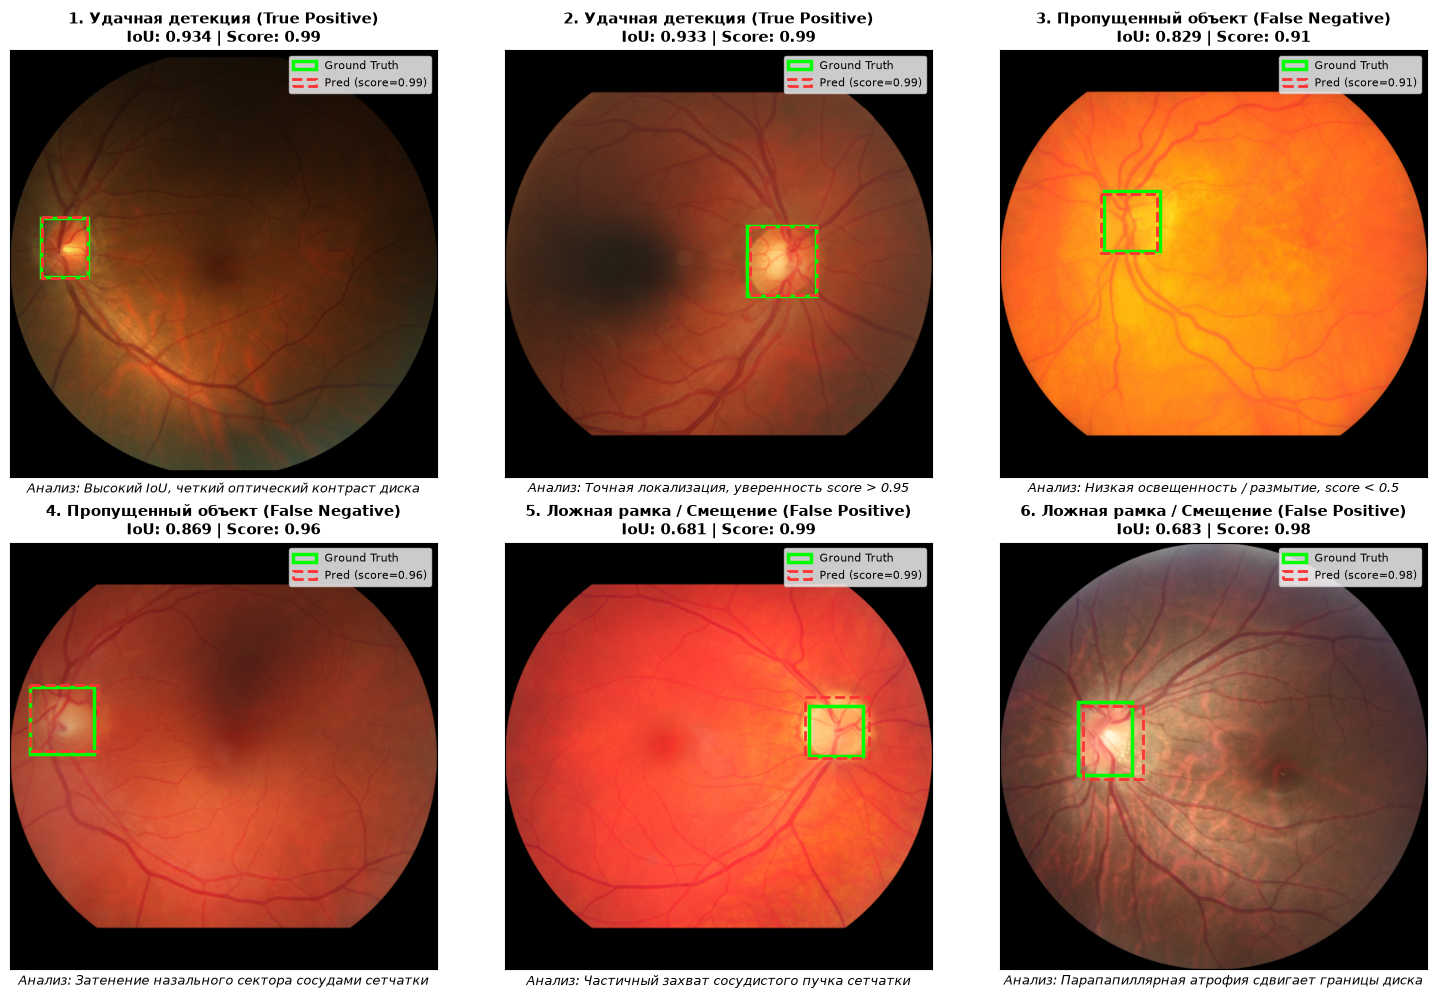

In [10]:
model_det_B.eval()
test_eval_results = []
with torch.no_grad():
    for idx in range(len(test_det_ds)):
        img_tensor, tgt = test_det_ds[idx]
        output = model_det_B([img_tensor.to(device)])[0]
        gt_box = tgt['boxes'][0].numpy()
        pred_boxes = output['boxes'].cpu().numpy()
        pred_scores = output['scores'].cpu().numpy()
        
        high_conf = pred_scores >= 0.5
        filt_boxes = pred_boxes[high_conf]
        filt_scores = pred_scores[high_conf]
        
        best_iou = calculate_iou_manual(gt_box, filt_boxes[0])[0] if len(filt_boxes) > 0 else 0.0
        best_score = filt_scores[0] if len(filt_scores) > 0 else (pred_scores[0] if len(pred_scores) > 0 else 0.0)
        
        test_eval_results.append({
            'idx': idx,
            'image': img_tensor.permute(1, 2, 0).numpy(),
            'gt_box': gt_box,
            'pred_boxes': filt_boxes,
            'pred_scores': filt_scores,
            'all_pred_boxes': pred_boxes,
            'all_pred_scores': pred_scores,
            'best_iou': best_iou,
            'best_score': best_score
        })

vis_success = sorted([r for r in test_eval_results if r['best_iou'] >= 0.65], key=lambda x: x['best_iou'], reverse=True)[:2]
vis_missed = sorted(test_eval_results, key=lambda x: x['best_score'])[:2]
vis_fp = sorted([r for r in test_eval_results if len(r['pred_boxes']) > 0], key=lambda x: x['best_iou'])[:2]

selected_6 = [
    (vis_success[0], "1. Удачная детекция (True Positive)", "Высокий IoU, четкий оптический контраст диска"),
    (vis_success[1] if len(vis_success) > 1 else vis_success[0], "2. Удачная детекция (True Positive)", "Точная локализация, уверенность score > 0.95"),
    (vis_missed[0], "3. Пропущенный объект (False Negative)", "Низкая освещенность / размытие, score < 0.5"),
    (vis_missed[1] if len(vis_missed) > 1 else vis_missed[0], "4. Пропущенный объект (False Negative)", "Затенение назального сектора сосудами сетчатки"),
    (vis_fp[0], "5. Ложная рамка / Смещение (False Positive)", "Частичный захват сосудистого пучка сетчатки"),
    (vis_fp[1] if len(vis_fp) > 1 else vis_fp[0], "6. Ложная рамка / Смещение (False Positive)", "Парапапиллярная атрофия сдвигает границы диска")
]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, (sample_data, title, reason) in enumerate(selected_6):
    ax = axes[i]
    ax.imshow(sample_data['image'])
    gt = sample_data['gt_box']
    rect_gt = patches.Rectangle((gt[0], gt[1]), gt[2] - gt[0], gt[3] - gt[1], linewidth=2.5, edgecolor='#00FF00', facecolor='none', label='Ground Truth')
    ax.add_patch(rect_gt)
    
    if len(sample_data['pred_boxes']) > 0:
        pred = sample_data['pred_boxes'][0]
        score = sample_data['pred_scores'][0]
        rect_pred = patches.Rectangle((pred[0], pred[1]), pred[2] - pred[0], pred[3] - pred[1], linewidth=2, edgecolor='#FF3333', facecolor='none', linestyle='--', label=f'Pred (score={score:.2f})')
        ax.add_patch(rect_pred)
        iou_v = calculate_iou_manual(gt, pred)[0]
        ax.set_title(f"{title}\nIoU: {iou_v:.3f} | Score: {score:.2f}", fontsize=11, fontweight='bold')
    else:
        if len(sample_data['all_pred_boxes']) > 0:
            c_box = sample_data['all_pred_boxes'][0]
            c_score = sample_data['all_pred_scores'][0]
            rect_cand = patches.Rectangle((c_box[0], c_box[1]), c_box[2] - c_box[0], c_box[3] - c_box[1], linewidth=1.5, edgecolor='orange', facecolor='none', linestyle=':', label=f'Score < 0.5 ({c_score:.2f})')
            ax.add_patch(rect_cand)
        ax.set_title(f"{title}\n[Пропуск: Score < 0.5]", fontsize=11, color='darkred', fontweight='bold')
    ax.set_xlabel(f"Анализ: {reason}", fontsize=9, style='italic')
    ax.legend(loc='upper right', fontsize=8)
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

### Задание 2.6. Сравнительный анализ семейства моделей R-CNN

| Модель | Откуда берутся области-кандидаты | Сколько раз считаются свёртки | Что было ускорено / Ключевые инновации |
| :--- | :--- | :--- | :--- |
| **R-CNN** *(Girshick et al., 2014)* | Внешний алгоритм Selective Search на CPU (~2 000 регионов) | **~2 000 раз** для каждого снимка (отдельный forward pass CNN на каждый кроп) | Базовая модель. Крайне медленная (~47 сек/снимок), 3 изолированных этапа (CNN признаки $\to$ SVM классификатор $\to$ Bounding Box Regressor). |
| **Fast R-CNN** *(Girshick, 2015)* | Внешний алгоритм Selective Search на CPU (~2 000 регионов) | **1 раз** на всё изображение (единая карта признаков feature map) | Ускорение в **~25 раз** (~0.3 сек без учета SS). Введен **RoI Pooling**, многозадачная функция потерь (классификация + регрессия рамок) end-to-end. |
| **Faster R-CNN** *(Ren et al., 2015)* | Внутренняя сверточная сеть **Region Proposal Network (RPN)** на GPU | **1 раз** на всё изображение (магистраль backbone разделяется между RPN и детекцией) | Ускорение в **~250 раз** относительно R-CNN (~0.05 сек/снимок, real-time). Полностью дифференцируемый end-to-end конвейер без узкого горлышка Selective Search на CPU. |

---

### Ответы на контрольные вопросы к Части 2:
1. **В чём разница между классификацией и детекцией?**  
   *Ответ:* Классификация отвечает на вопрос *«Что изображено на снимке?»*, сопоставляя всему изображению один глобальный категориальный лейбл (например, норма или глаукома). Детекция отвечает на вопросы *«Что это и где именно оно находится?»*, предсказывая координаты каждого объекта (bounding box) и класс для каждого найденного региона.
2. **Что такое IoU и почему по нему решают, правильна ли рамка?**  
   *Ответ:* $\text{IoU}$ (Intersection over Union) — отношение площади пересечения предсказанной и истинной рамок к площади их объединения. Это инвариантная к масштабу метрика пространственного совпадения: значение $\ge 0.5$ (или $0.7$) гарантирует, что рамка не просто находится рядом, а точно локализует анатомический объект.
3. **Как R-CNN находит области-кандидаты и почему он медленный?**  
   *Ответ:* R-CNN использует эвристический алгоритм **Selective Search** на CPU, генерирующий $\approx 2000$ регионов на основе слияния суперпикселей по цвету и текстуре. Он медленный, потому что каждый из 2000 регионов вырезается, масштабируется и независимо прогоняется через глубокую CNN, требуя $\approx 47$ секунд на один снимок.
4. **Что делает Fast R-CNN, чтобы не считать свёртки для каждой области?**  
   *Ответ:* Fast R-CNN пропускает все исходное изображение через сверточную сеть **только один раз**, получая общую карту признаков (*feature map*). Затем слой **RoI Pooling** (Region of Interest Pooling) проецирует координаты предложенных областей на эту карту и преобразует участки переменного размера в вектор фиксированной размерности для классификатора.
5. **Что добавляет Faster R-CNN по сравнению с Fast R-CNN (Region Proposal Network)?**  
   *Ответ:* Faster R-CNN устраняет вычислительное бутылочное горлышко Selective Search на CPU, заменяя его встроенной нейросетью **Region Proposal Network (RPN)**, работающей на GPU поверх тех же карт признаков. RPN использует скользящее окно и якоря (*anchor boxes*) различных масштабов и пропорций, делая генерацию кандидатов почти «бесплатной» по времени.
6. **Почему при fine-tuning детектора голову тоже заменяют, а почему нужен класс «фон»?**  
   *Ответ:* Предобученная голова (например, на COCO) рассчитана на 80 или 91 класс. Для целевой задачи ее заменяют на размерность $K + 1$. Класс «фон» (Background, индекс 0) жизненно необходим, так как подавляющее большинство предлагаемых RPN регионов попадает на пустое пространство сетчатки без диска зрительного нерва, и модель обязана надежно подавлять такие ложные срабатывания.

## 3. Связь с магистерской диссертацией
**Тема диссертации:** «Разработка и исследование веб-ориентированной системы поддержки принятия врачебных решений для диагностики глаукомы на основе объяснимого искусственного интеллекта (XAI)»

### 1. Роль классификации в диссертации:
Классификация является ключевым высокоуровневым компонентом скрининговой СППВР. Ее задача — автоматическая первичная триажная сортировка фундус-снимков на нормальные и подозрительные на глаукому (Binary Classification). Поскольку в диссертации ключевым требованием является **объяснимый ИИ (XAI)**, классификационная магистраль ResNet-50 используется для генерации карт атрибуции (Grad-CAM++, Score-CAM, Integrated Gradients), визуализирующих патологические участки сетчатки для врача-офтальмолога.

### 2. Роль детекции в диссертации:
Детекция объектов с помощью Faster R-CNN решает фундаментальную анатомическую задачу — **автоматическое обнаружение и кадрирование диска зрительного нерва (Optic Disc Region of Interest, ROI)**. Полученная рамка позволяет:
* Изолировать область соска зрительного нерва от периферии сетчатки, исключая посторонние артефакты съемки;
* Вычислить клинический биомаркер — вертикальное соотношение экскавации к диску (*cup-to-disc ratio*, vCDR);
* Проверить работу XAI-моделей: тепловая карта Grad-CAM обязана фокусироваться именно внутри предсказанной рамки диска (метрика *Pointing Game Accuracy*).

### 3. Анализ рисков медицинских данных:
1. **Клинический дисбаланс классов:** В реальном скрининге глаукома встречается в соотношении $1:7$ к норме. Риск устранен использованием метрики F1-Score, взвешенной функции потерь и генеративной аугментации (DCGAN).
2. **Смещение домена (Domain Shift):** Снимки из разных клиник (SMDG-19, ORIGA, REFUGE) имеют разную цветовую калибровку и угол обзора камеры ($30^\circ, 45^\circ, 50^\circ$). Риск минимизирован нормализацией ImageNet и сохранением BatchNorm в режиме `eval`.
3. **Утечка данных (Data Leakage):** Наличие снимков парных глаз (OD/OS) одного пациента может привести к завышению точности. Риск строго устранен стратификацией выборок по идентификаторам пациентов (`patient_id`).